In [2]:
import pandas as pd

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Module12/data/customer_segmentation.csv")

In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

data = df.drop(columns="customer_id")

X = scaler.fit_transform(data)

model = KMeans(n_clusters=4, n_init=10)

model.fit(X)

data["cluster"] = model.labels_

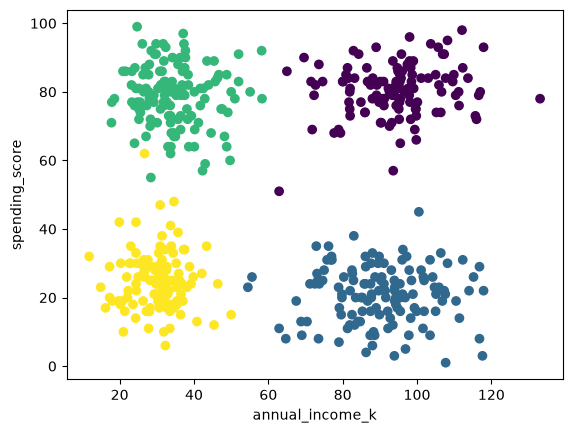

In [14]:
import matplotlib.pyplot as plt

plt.scatter(data["annual_income_k"], data["spending_score"], c=data["cluster"])
plt.xlabel("annual_income_k")
plt.ylabel("spending_score")
plt.show()

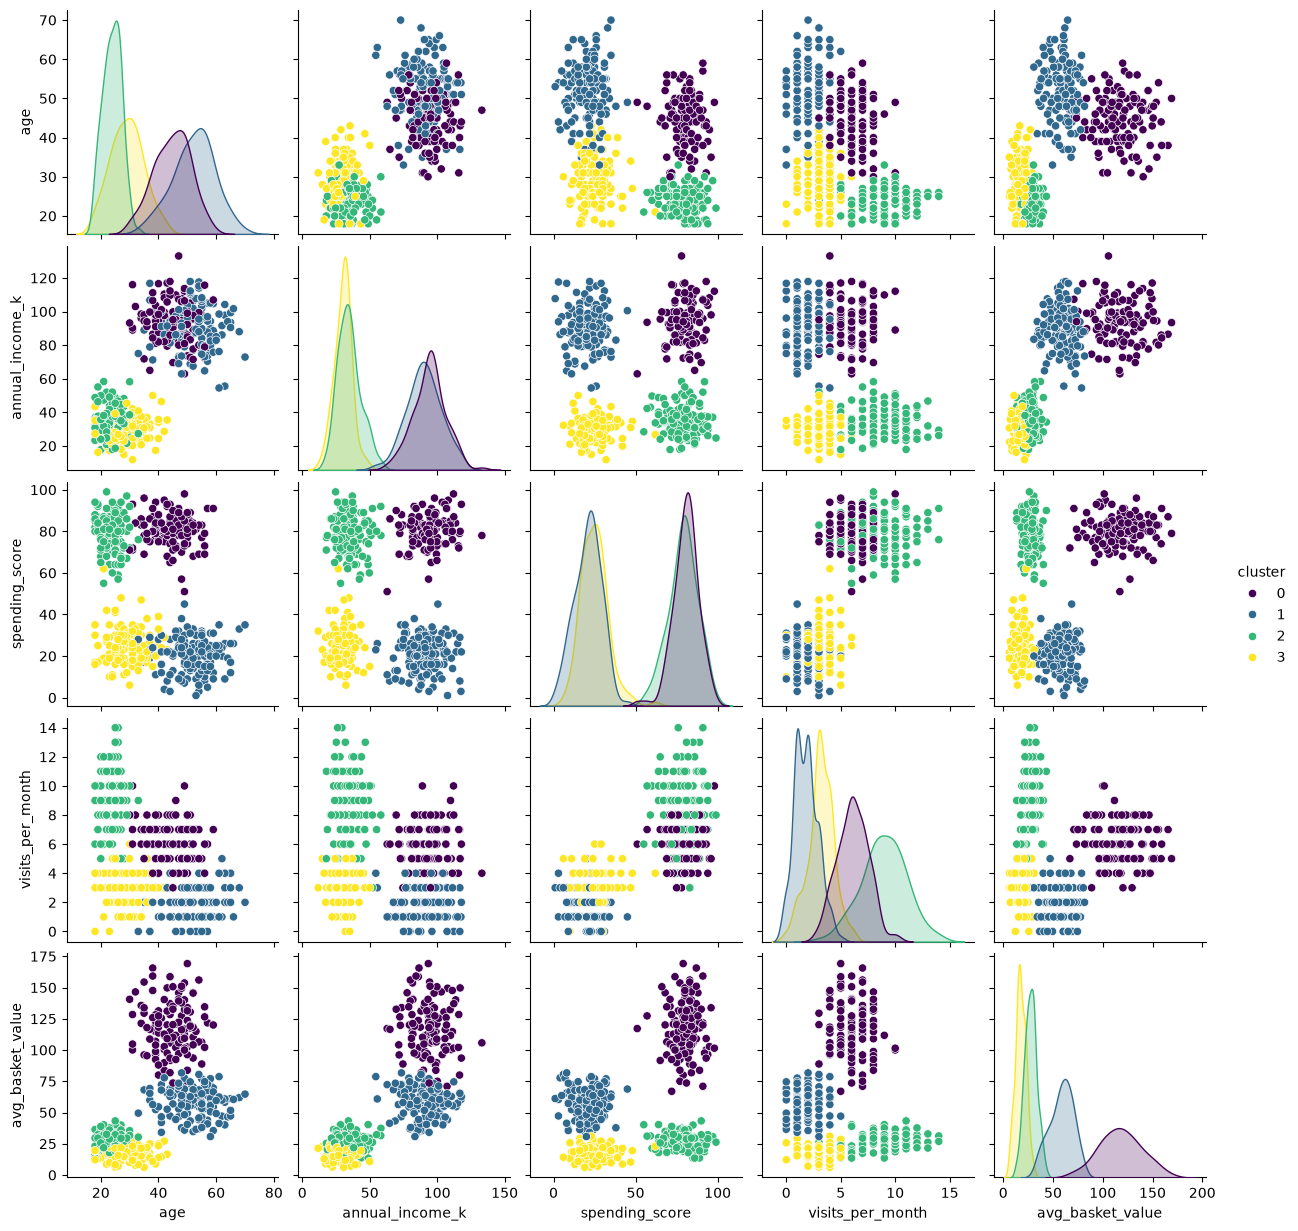

In [17]:
import seaborn as sns

sns.pairplot(data, hue="cluster", palette="viridis")

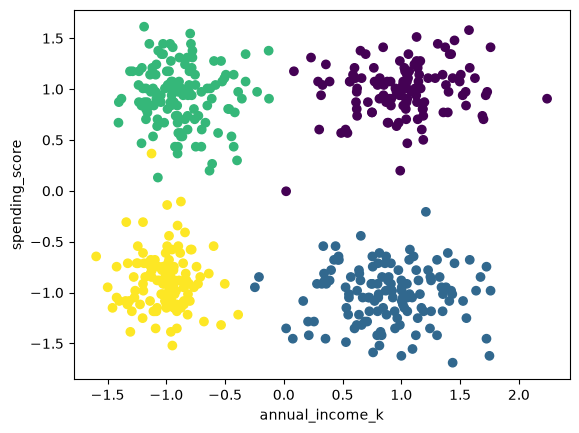

In [20]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 1], X[:, 2], c=model.labels_)
plt.xlabel(data.columns[1])
plt.ylabel(data.columns[2])
plt.show()

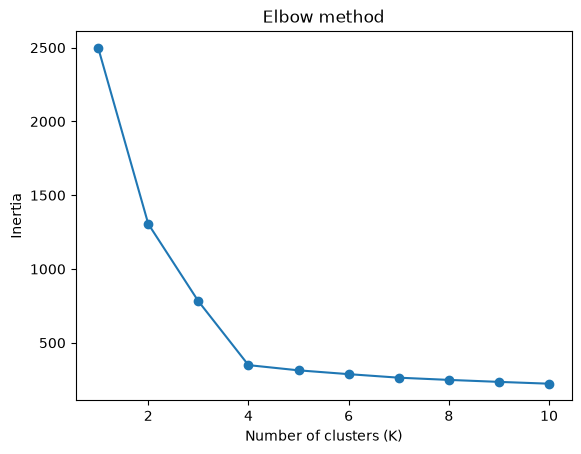

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

In [10]:
data.columns

Index(['age', 'annual_income_k', 'spending_score', 'visits_per_month',
       'avg_basket_value'],
      dtype='str')

In [11]:
model4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
data["cluster"] = model4.labels_

print(data.groupby("cluster").mean().round(1))

          age  annual_income_k  spending_score  visits_per_month  \
cluster                                                            
0        23.9             34.7            78.9               9.0   
1        52.2             90.2            20.8               1.8   
2        29.0             30.1            24.9               3.1   
3        44.7             94.2            80.6               6.1   

         avg_basket_value  
cluster                    
0                    27.4  
1                    58.4  
2                    17.4  
3                   117.9  
